___
<h1> Machine Learning </h1>
<h2> M. Sc. in Electrical and Computer Engineering </h2>
<h3> Instituto Superior de Engenharia / Universidade do Algarve </h3>

[MEEC](https://ise.ualg.pt/en/curso/1477) / [ISE](https://ise.ualg.pt) / [UAlg](https://www.ualg.pt)

Pedro J. S. Cardoso (pcardoso@ualg.pt)
___

# ANN: multilayer networks

A multilayer network has one or more hidden layers between the input and the output. This notebook trains them with scikit-learn (`MLPClassifier` and `MLPRegressor`) and with Keras, including dropout and L1/L2 penalties.


## Multi-layer Perceptron (MLP) Classification: Iris dataset
In this section, we'll use the Iris dataset to make out first example.

So, load and split data:

In [1]:
from sklearn.datasets import load_iris, load_digits
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [2]:
iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, 
    iris.target,
    stratify=iris.target,
    random_state=1
)

Prepare a multi-layer perceptron classifier (MLPClassifier), train and get the score over the test data

(https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html)

The default parameters are:
- hidden_layer_sizes=(100,)
- activation='relu'
- solver='adam'
- alpha=0.0001
- ...

In [3]:
clf = MLPClassifier(
    verbose=True,  # uncomment to see loss function evolution
    random_state=1
).fit(X_train, y_train)

score = clf.score(X_test, y_test)
print(f'Final score: {score}')

Iteration 1, loss = 1.66464854
Iteration 2, loss = 1.59642491
Iteration 3, loss = 1.53212459
Iteration 4, loss = 1.47209278
Iteration 5, loss = 1.41663620
Iteration 6, loss = 1.36599559
Iteration 7, loss = 1.32054743
Iteration 8, loss = 1.28064650
Iteration 9, loss = 1.24632752
Iteration 10, loss = 1.21751133
Iteration 11, loss = 1.19372622
Iteration 12, loss = 1.17425626
Iteration 13, loss = 1.15814594
Iteration 14, loss = 1.14436045
Iteration 15, loss = 1.13186477
Iteration 16, loss = 1.11985835
Iteration 17, loss = 1.10755920
Iteration 18, loss = 1.09437060
Iteration 19, loss = 1.08015249
Iteration 20, loss = 1.06496098
Iteration 21, loss = 1.04894819
Iteration 22, loss = 1.03240511
Iteration 23, loss = 1.01571312
Iteration 24, loss = 0.99922988
Iteration 25, loss = 0.98321368
Iteration 26, loss = 0.96793651
Iteration 27, loss = 0.95352527
Iteration 28, loss = 0.94003400
Iteration 29, loss = 0.92742638
Iteration 30, loss = 0.91552994
Iteration 31, loss = 0.90420939
Iteration 32, los

/opt/anaconda3/envs/ML/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


You probably got a warning message related to the number of iterations. The default number of iterations is 200. The warning message is due to the fact that the optimization algorithm did not converge. 

ok...!? let us see if we can improve this... by increasing the number of iterations

In [4]:
clf = MLPClassifier(
    max_iter=1000,
    random_state=1,
    verbose=True
).fit(X_train, y_train)

score = clf.score(X_test, y_test)
print(f'Final score: {score}')

Iteration 1, loss = 1.66464854
Iteration 2, loss = 1.59642491
Iteration 3, loss = 1.53212459
Iteration 4, loss = 1.47209278
Iteration 5, loss = 1.41663620
Iteration 6, loss = 1.36599559
Iteration 7, loss = 1.32054743
Iteration 8, loss = 1.28064650
Iteration 9, loss = 1.24632752
Iteration 10, loss = 1.21751133
Iteration 11, loss = 1.19372622
Iteration 12, loss = 1.17425626
Iteration 13, loss = 1.15814594
Iteration 14, loss = 1.14436045
Iteration 15, loss = 1.13186477
Iteration 16, loss = 1.11985835
Iteration 17, loss = 1.10755920
Iteration 18, loss = 1.09437060
Iteration 19, loss = 1.08015249
Iteration 20, loss = 1.06496098
Iteration 21, loss = 1.04894819
Iteration 22, loss = 1.03240511
Iteration 23, loss = 1.01571312
Iteration 24, loss = 0.99922988
Iteration 25, loss = 0.98321368
Iteration 26, loss = 0.96793651
Iteration 27, loss = 0.95352527
Iteration 28, loss = 0.94003400
Iteration 29, loss = 0.92742638
Iteration 30, loss = 0.91552994
Iteration 31, loss = 0.90420939
Iteration 32, los

That was good! Maybe there were other alternatives, like using more layers...?

In [5]:
clf = MLPClassifier(
    hidden_layer_sizes=(100, 100),
    random_state=1,
    max_iter=1000,
    verbose=True
).fit(X_train, y_train)

score = clf.score(X_test, y_test)
print(f'Final score: {score}')

Iteration 1, loss = 1.13813496
Iteration 2, loss = 1.09744719
Iteration 3, loss = 1.05909000
Iteration 4, loss = 1.02139912
Iteration 5, loss = 0.98499298
Iteration 6, loss = 0.94953560
Iteration 7, loss = 0.91516216
Iteration 8, loss = 0.88424902
Iteration 9, loss = 0.85705669
Iteration 10, loss = 0.83120918
Iteration 11, loss = 0.80695608
Iteration 12, loss = 0.78443382
Iteration 13, loss = 0.76272088
Iteration 14, loss = 0.74164135
Iteration 15, loss = 0.72132565
Iteration 16, loss = 0.70265090
Iteration 17, loss = 0.68511207
Iteration 18, loss = 0.66800111
Iteration 19, loss = 0.65134797
Iteration 20, loss = 0.63508628
Iteration 21, loss = 0.61913530
Iteration 22, loss = 0.60358210
Iteration 23, loss = 0.58848308
Iteration 24, loss = 0.57385041
Iteration 25, loss = 0.55969161
Iteration 26, loss = 0.54605180
Iteration 27, loss = 0.53292334
Iteration 28, loss = 0.52035146
Iteration 29, loss = 0.50848838
Iteration 30, loss = 0.49720142
Iteration 31, loss = 0.48634666
Iteration 32, los

Being a __multi-class classification problem__, the output layer has three neurons (one for each class: setosa, versicolor, and virginica). The __activation function is a softmax function__, which is a generalization of the logistic function to multiple dimensions. 

The sotmax function allows us to interpret the output of the network as probabilities. The class with the highest probability is the predicted class. The probabilities associated to each test instance are: 

In [6]:
clf.predict_proba(X_test)

array([[7.86144763e-08, 4.93910629e-04, 9.99506011e-01],
       [9.99861924e-01, 1.38076128e-04, 6.32453898e-12],
       [9.99928540e-01, 7.14599293e-05, 2.53030936e-12],
       [9.99795496e-01, 2.04503696e-04, 1.28526645e-11],
       [9.64648544e-04, 9.98941162e-01, 9.41896030e-05],
       [9.99861275e-01, 1.38724552e-04, 7.17099837e-12],
       [1.36006199e-04, 9.99363848e-01, 5.00145784e-04],
       [7.60896909e-06, 2.03406360e-02, 9.79651755e-01],
       [9.99662815e-01, 3.37184947e-04, 2.50192488e-11],
       [7.15431806e-05, 9.96205204e-01, 3.72325320e-03],
       [9.72449046e-09, 1.20821608e-03, 9.98791774e-01],
       [2.68612715e-05, 2.76217555e-01, 7.23755584e-01],
       [6.29665021e-07, 2.96229201e-03, 9.97037078e-01],
       [4.63644444e-05, 9.88526539e-01, 1.14270968e-02],
       [1.10236139e-07, 2.72959667e-03, 9.97270293e-01],
       [2.42998054e-05, 9.94530144e-01, 5.44555662e-03],
       [1.26652828e-07, 1.63849176e-03, 9.98361382e-01],
       [4.46274004e-05, 9.97263

Let us see the distribution of the probabilities, for each class, over the test data. This allows us to understand the confidence of the classifier in its predictions.

(array([[26.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0., 12.],
        [24.,  0.,  1.,  0.,  0.,  0.,  1.,  0.,  0., 12.],
        [24.,  0.,  0.,  1.,  0.,  0.,  0.,  1.,  0., 12.]]),
 array([6.35835833e-14, 9.99993020e-02, 1.99998604e-01, 2.99997906e-01,
        3.99997208e-01, 4.99996510e-01, 5.99995812e-01, 6.99995114e-01,
        7.99994416e-01, 8.99993718e-01, 9.99993020e-01]),
 <a list of 3 BarContainer objects>)

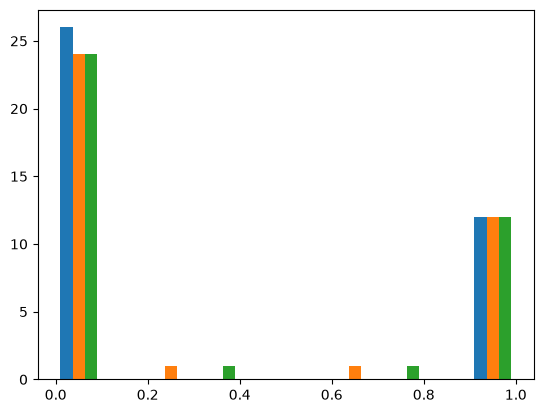

In [7]:
plt.hist(clf.predict_proba(X_test))

## Multi-layer Perceptron (MLP) Regression: Bike Sharing dataset

In this section, we'll use the Bike Sharing dataset to make a regression example. This dataset contains the hourly count of rental bikes between years 2017 and 2018 in Seoul, Korea. The goal is to predict the number of bikes rented in a given hour based on the features available.

In [8]:
df = pd.read_csv('./data/SeoulBikeData.csv')
df.head()

,Date,Rented Bike Count,Hour,Temperature(C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


As we can see, the dataset contains both numerical and categorical data. The target variable is the number of rented bikes.

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Date                      8760 non-null   object 
 1   Rented Bike Count         8760 non-null   int64  
 2   Hour                      8760 non-null   int64  
 3   Temperature(C)            8760 non-null   float64
 4   Humidity(%)               8760 non-null   int64  
 5   Wind speed (m/s)          8760 non-null   float64
 6   Visibility (10m)          8760 non-null   int64  
 7   Dew point temperature(C)  8760 non-null   float64
 8   Solar Radiation (MJ/m2)   8760 non-null   float64
 9   Rainfall(mm)              8760 non-null   float64
 10  Snowfall (cm)             8760 non-null   float64
 11  Seasons                   8760 non-null   object 
 12  Holiday                   8760 non-null   object 
 13  Functioning Day           8760 non-null   object 
dtypes: float

First, we pre-process the data:
- transform the date into a datetime object and extract the hour
- replacing the categorical data by one-hot encoding and normalizing the numerical data.

In [10]:
df['Date'] = pd.to_datetime(df['Date'], format='%d/%m/%Y')
df['hour'] = df['Date'].dt.hour
df['month'] = df['Date'].dt.month
df.drop(columns=['Date'], inplace=True)

df = pd.get_dummies(df, columns=['Seasons', 'Holiday', 'Functioning Day'])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Rented Bike Count         8760 non-null   int64  
 1   Hour                      8760 non-null   int64  
 2   Temperature(C)            8760 non-null   float64
 3   Humidity(%)               8760 non-null   int64  
 4   Wind speed (m/s)          8760 non-null   float64
 5   Visibility (10m)          8760 non-null   int64  
 6   Dew point temperature(C)  8760 non-null   float64
 7   Solar Radiation (MJ/m2)   8760 non-null   float64
 8   Rainfall(mm)              8760 non-null   float64
 9   Snowfall (cm)             8760 non-null   float64
 10  hour                      8760 non-null   int32  
 11  month                     8760 non-null   int32  
 12  Seasons_Autumn            8760 non-null   bool   
 13  Seasons_Spring            8760 non-null   bool   
 14  Seasons_

Now we split the data into features and target.

In [11]:
X_Seoul = df.drop(columns=['Rented Bike Count'])
y_Seoul = df['Rented Bike Count']

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X_Seoul, 
    y_Seoul,
    test_size=0.8,
    random_state=42
)

Fit `StandardScaler` on the **training set only**, then transform the test set with the same mean and standard deviation. Fitting on all of `X` would leak test-set statistics into the features.

In [13]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Prepare a multi-layer perceptron regressor (MLPRegressor), train and get the score over the test data

In [14]:
model = MLPRegressor(
    max_iter=200,
    random_state=1,
    verbose=True
    ).fit(X_train, y_train)

score = model.score(X_test, y_test)
print(f'Final score (R2): {score}')

Iteration 1, loss = 451664.07487876
Iteration 2, loss = 451358.82236483
Iteration 3, loss = 451055.34209234
Iteration 4, loss = 450756.15342142
Iteration 5, loss = 450437.27910007
Iteration 6, loss = 450093.66923832
Iteration 7, loss = 449721.54337359
Iteration 8, loss = 449302.38936589
Iteration 9, loss = 448840.01466525
Iteration 10, loss = 448310.99854542
Iteration 11, loss = 447723.15003186
Iteration 12, loss = 447061.30662142
Iteration 13, loss = 446317.54742327
Iteration 14, loss = 445516.68099371
Iteration 15, loss = 444595.97688481
Iteration 16, loss = 443603.63038021
Iteration 17, loss = 442541.01953298
Iteration 18, loss = 441369.20241851
Iteration 19, loss = 440119.37901973
Iteration 20, loss = 438791.48795450
Iteration 21, loss = 437364.75578883
Iteration 22, loss = 435864.15371647
Iteration 23, loss = 434243.72132831
Iteration 24, loss = 432561.44095919
Iteration 25, loss = 430826.28908130
Iteration 26, loss = 428975.72837512
Iteration 27, loss = 426991.28079242
Iteration 

/opt/anaconda3/envs/ML/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


You probably got a warning message related to the number of iterations. The default number of iterations is 200. The warning message is due to the fact that the optimization algorithm did not converge. So, let us increase the number of iterations.

In [15]:
model = MLPRegressor(max_iter=20000,
                     random_state=1,
                     verbose=True
                     ).fit(X_train, y_train)

score = model.score(X_test, y_test)
print(f'Final score (R2): {score}')

Iteration 1, loss = 451664.07487876
Iteration 2, loss = 451358.82236483
Iteration 3, loss = 451055.34209234
Iteration 4, loss = 450756.15342142
Iteration 5, loss = 450437.27910007
Iteration 6, loss = 450093.66923832
Iteration 7, loss = 449721.54337359
Iteration 8, loss = 449302.38936589
Iteration 9, loss = 448840.01466525
Iteration 10, loss = 448310.99854542
Iteration 11, loss = 447723.15003186
Iteration 12, loss = 447061.30662142
Iteration 13, loss = 446317.54742327
Iteration 14, loss = 445516.68099371
Iteration 15, loss = 444595.97688481
Iteration 16, loss = 443603.63038021
Iteration 17, loss = 442541.01953298
Iteration 18, loss = 441369.20241851
Iteration 19, loss = 440119.37901973
Iteration 20, loss = 438791.48795450
Iteration 21, loss = 437364.75578883
Iteration 22, loss = 435864.15371647
Iteration 23, loss = 434243.72132831
Iteration 24, loss = 432561.44095919
Iteration 25, loss = 430826.28908130
Iteration 26, loss = 428975.72837512
Iteration 27, loss = 426991.28079242
Iteration 

It's better... but maybe we can improve this... by increasing the number of hidden layers and neurons.
The previous model has only one hidden layer with 100 neurons. We can try to improve the model by adding more layers and neurons, for example:

In [16]:
model = MLPRegressor(
    max_iter=2000,
    hidden_layer_sizes=(100, 100, 100),
    random_state=1,
    verbose=True
).fit(X_train, y_train)

score = model.score(X_test, y_test)
print(f'Final score (R2): {score}')

Iteration 1, loss = 450861.68169152
Iteration 2, loss = 448964.17827016
Iteration 3, loss = 444870.36784071
Iteration 4, loss = 436125.09132198
Iteration 5, loss = 418779.56115030
Iteration 6, loss = 387512.92104908
Iteration 7, loss = 335618.57195934
Iteration 8, loss = 265068.98245134
Iteration 9, loss = 181493.92589690
Iteration 10, loss = 123332.27637471
Iteration 11, loss = 110274.28289182
Iteration 12, loss = 103881.48640936
Iteration 13, loss = 95945.12847259
Iteration 14, loss = 92562.00259814
Iteration 15, loss = 89313.40670542
Iteration 16, loss = 87137.25461795
Iteration 17, loss = 85037.20791715
Iteration 18, loss = 83571.42691829
Iteration 19, loss = 82347.02083747
Iteration 20, loss = 81352.58565178
Iteration 21, loss = 80435.46671639
Iteration 22, loss = 79710.20921936
Iteration 23, loss = 79030.36070676
Iteration 24, loss = 78474.76538852
Iteration 25, loss = 78034.49775315
Iteration 26, loss = 77435.05167759
Iteration 27, loss = 77089.51665980
Iteration 28, loss = 7679

A slightly better result was obtained. We can try to improve the model by adding more layers and neurons... or we can use a different activation function. The default activation function is the ReLU function. Try it...!

To compare the predicted values with the true values we can plot them.

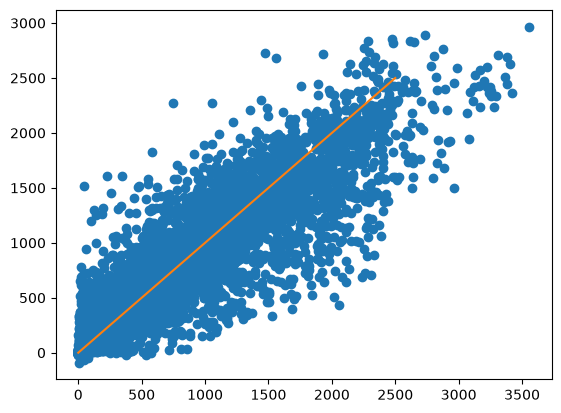

In [17]:
y_pred = model.predict(X_test)
plt.plot(y_test, y_pred, 'o')
plt.plot([0,2500], [0,2500], '-', label='test')

# ANN with Keras

Keras is a high-level neural networks API. A model is a stack of layers. `compile` chooses the optimizer and the loss, and `fit` runs the training.

If a GPU is visible, `fit` uses it. On a Mac that device is the Metal GPU. Otherwise training stays on the CPU.

In this section the network classifies the digits dataset and predicts the number of bikes rented in a given hour.


In [18]:
import tensorflow as tf

# Use a GPU when TensorFlow can see one. On a Mac that device is the Metal GPU.
gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

if gpus:
    names = []
    for gpu in gpus:
        info = tf.config.experimental.get_device_details(gpu)
        names.append(info.get("device_name", gpu.name))
    print("Training on", ", ".join(names))
else:
    print("No GPU or Metal device visible. Training on CPU.")

from keras.models import Sequential
from keras.layers import Dense, Input, Dropout
from keras.utils import to_categorical

from tensorflow.keras.utils import plot_model

tf.random.set_seed(42)


Training on METAL


## Classification: Digits dataset

The digits dataset consists of 8x8 pixel images. The goal is to classify each image into one of ten classes (0-9).

First we load the data, scale it, and split it into training, validation, and test sets. Then we build a network, train it, and evaluate it on the test data.


In [19]:
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_digits
digits = load_digits()      # We are using the digits dataset, from sklearn.datasets 
X = digits.data
y = digits.target

# Normalize data - values are between 0 and 16
X = X / 16.0

One-hot encode the labels. The output layer has 10 neurons, one per digit, and a softmax activation. Softmax returns a probability for each class, so the label of one example is a row of 10 numbers: 1 for the true class and 0 for the others.

- if the label is 0, the one-hot row is [1, 0, 0, 0, 0, 0, 0, 0, 0, 0]
- if the label is 1, the one-hot row is [0, 1, 0, 0, 0, 0, 0, 0, 0, 0]

Softmax turns the 10 scores \(x_i\) into probabilities
$$
y_i = \frac{e^{x_i}}{\sum_{j=1}^{n} e^{x_j}}.
$$


In [20]:
y = to_categorical(y)
y[:5]


array([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 1., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0., 0., 0., 0., 0.]])

Split data into training, validation, and test sets


In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.3,
                                                    random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_test, y_test,
                                                test_size=0.5,
                                                random_state=42)


The network has:
- an input of 64 values, one per pixel,
- two hidden layers of 100 units, with ReLU,
- a dropout layer, which sets 10% of those units to zero during training,
- an output of 10 units, one per digit, with softmax.


In [22]:
tf.random.set_seed(42)

m, n = X_train.shape

model = Sequential()
model.add(Input(shape=(n,)))
model.add(Dense(100, activation='relu'))
model.add(Dropout(0.1))
model.add(Dense(100, activation='relu'))
model.add(Dense(10, activation='softmax'))


I0000 00:00:1793120021.704669 23169371 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1793120021.704691 23169371 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 36038 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)
W0000 00:00:1793120021.756740 23169371 metal_kernel_util.mm:220] Metal: this TensorFlow does not export the kernel C API for resource variables, so its own kernels update variables from the host. Every Metal kernel now waits for the GPU before returning, which is slower and is the only way those updates cannot race. See https://github.com/tensorflow/tensorflow/issues/126374.


`compile` sets the optimizer, the loss, and the metrics. Categorical cross-entropy compares the softmax output with the one-hot label. The optimizer is Adam.


In [23]:
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

The shapes of the layers are:


In [24]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 100)            │         6,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,610 (68.79 KB)

 Trainable params: 17,610 (68.79 KB)

 Non-trainable params: 0 (0.00 B)

A plot of the architecture is:


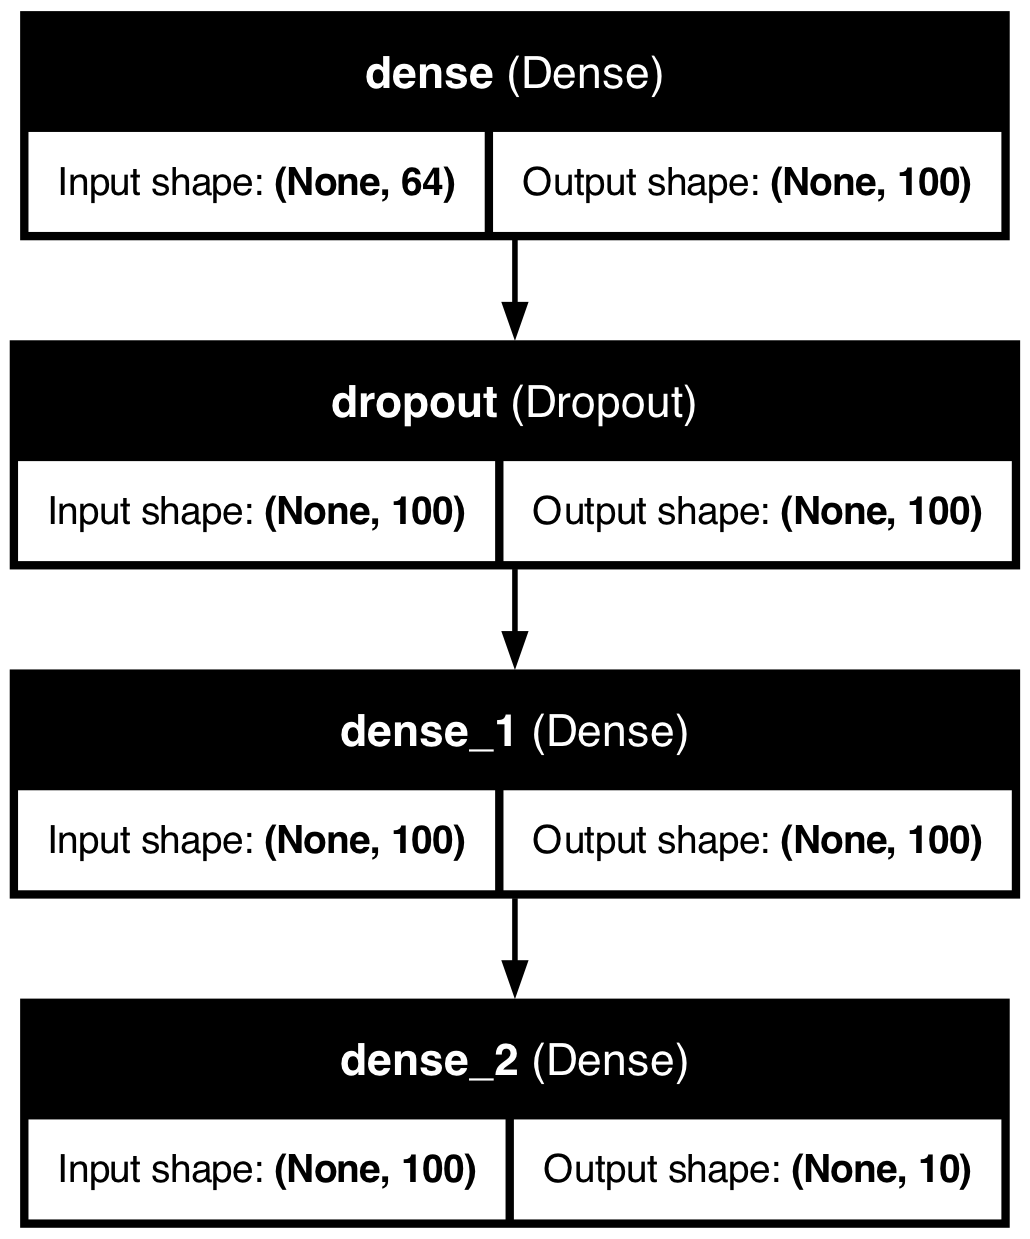

In [25]:
plot_model(
    model, 
    to_file='model_architecture.png', 
    show_shapes=True, 
    show_layer_names=True
)

In [26]:
model.fit(
    X_train, 
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32
)


Epoch 1/100


I0000 00:00:1793120022.478577 23169371 custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.4574 - loss: 1.9385 - val_accuracy: 0.6556 - val_loss: 1.4662
Epoch 2/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.8019 - loss: 1.0240 - val_accuracy: 0.8778 - val_loss: 0.6081
Epoch 3/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.8966 - loss: 0.4689 - val_accuracy: 0.9185 - val_loss: 0.3397
Epoch 4/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.9085 - loss: 0.3127 - val_accuracy: 0.9259 - val_loss: 0.2642
Epoch 5/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.9443 - loss: 0.2289 - val_accuracy: 0.9370 - val_loss: 0.2129
Epoch 6/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.9483 - loss: 0.1969 - val_accuracy: 0.9370 - val_loss: 0.1908
Epoch 7/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.9507 - loss: 0.1673 - val_accuracy: 0.9407 - val_loss: 0.1667
Epoch 8/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.9610 - loss: 0.1448 - val_accuracy: 0.9481 - val_l

Let us see the loss evolution during training and check if there was overfitting.


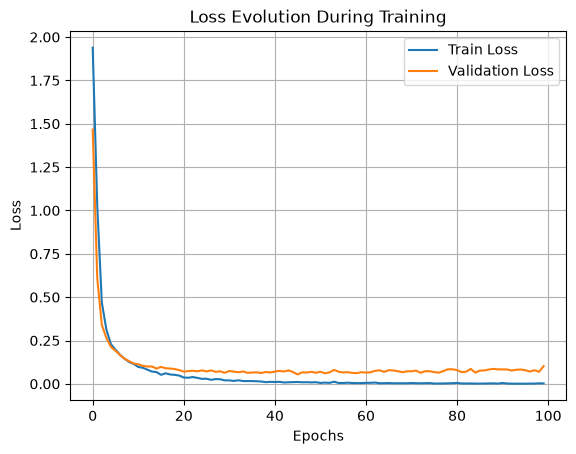

In [27]:
import matplotlib.pyplot as plt

def plot_history(model):
    history = model.history
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Loss Evolution During Training')
    plt.legend()
    plt.grid()
    plt.show()

plot_history(model)


In [28]:
res = model.evaluate(X_test, y_test)
print(f'Test loss: {res[0]:.4f}')
print(f'Test accuracy: {res[1]:.4f}')


9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9778 - loss: 0.1110 
Test loss: 0.1110
Test accuracy: 0.9778


The plot shows that after ~30 epochs there is no improvement in the validation accuracy. So let us train a model with 30 epochs

Epoch 1/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.4463 - loss: 1.9963 - val_accuracy: 0.7741 - val_loss: 1.5303
Epoch 2/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.8218 - loss: 1.0648 - val_accuracy: 0.8926 - val_loss: 0.5871
Epoch 3/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.8918 - loss: 0.4691 - val_accuracy: 0.9296 - val_loss: 0.3067
Epoch 4/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.9212 - loss: 0.3034 - val_accuracy: 0.9407 - val_loss: 0.2269
Epoch 5/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.9491 - loss: 0.2161 - val_accuracy: 0.9444 - val_loss: 0.1927
Epoch 6/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.9483 - loss: 0.1853 - val_accuracy: 0.9519 - val_loss: 0.1646
Epoch 7/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.9570 - loss: 0.1599 - val_accuracy: 0.9556 - val_loss: 0.1498
Epoch 8/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.9594 - loss: 0.1383 - val_accuracy: 0.9593 - v

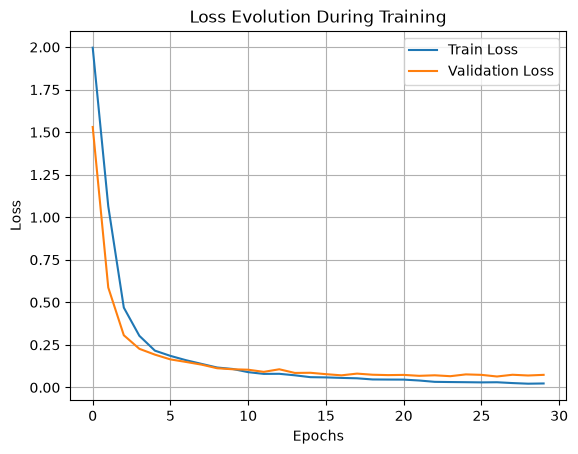

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9704 - loss: 0.0923
Test loss: 0.0923
Test accuracy: 0.9704


In [29]:
#reset the seed
tf.random.set_seed(42)

model = Sequential()
model.add(Input(shape=(n,)))
model.add(Dense(100, activation='relu'))
model.add(Dropout(0.1))
model.add(Dense(100, activation='relu'))
model.add(Dense(10, activation='softmax'))

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.fit(X_train, y_train,
          validation_data=(X_val, y_val),
          epochs=30,
          batch_size=32)

plot_history(model)

res = model.evaluate(X_test, y_test)
print(f'Test loss: {res[0]:.4f}')
print(f'Test accuracy: {res[1]:.4f}')

## Regression: Bike Sharing dataset

The same `fit` call, with a linear output and squared error, predicts the number of bikes rented in a given hour.


In [30]:
import pandas as pd
df = pd.read_csv('./data/SeoulBikeData.csv')
df.head()

,Date,Rented Bike Count,Hour,Temperature(C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


First, we prepossess the data:
- transform the date into a datetime object and extract the hour
- replacing the categorical data by one-hot encoding and normalizing the numerical data.

In [31]:
df['Date'] = pd.to_datetime(df['Date'], format='%d/%m/%Y')
df['hour'] = df['Date'].dt.hour
df['month'] = df['Date'].dt.month
df.drop(columns=['Date'], inplace=True)

df = pd.get_dummies(df, columns=['Seasons', 'Holiday', 'Functioning Day'])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Rented Bike Count         8760 non-null   int64  
 1   Hour                      8760 non-null   int64  
 2   Temperature(C)            8760 non-null   float64
 3   Humidity(%)               8760 non-null   int64  
 4   Wind speed (m/s)          8760 non-null   float64
 5   Visibility (10m)          8760 non-null   int64  
 6   Dew point temperature(C)  8760 non-null   float64
 7   Solar Radiation (MJ/m2)   8760 non-null   float64
 8   Rainfall(mm)              8760 non-null   float64
 9   Snowfall (cm)             8760 non-null   float64
 10  hour                      8760 non-null   int32  
 11  month                     8760 non-null   int32  
 12  Seasons_Autumn            8760 non-null   bool   
 13  Seasons_Spring            8760 non-null   bool   
 14  Seasons_

Now we split the data into features and target.

In [32]:
X = df.drop(columns=['Rented Bike Count'])
y = df['Rented Bike Count']

Split into training, validation, and test sets **before** scaling.

In [33]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_test, y_test,
    test_size=0.5,
    random_state=42
)

Fit `StandardScaler` on the training set only. Use `transform` (not `fit_transform`) on the validation and test sets.

In [34]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

The network has:
- one input per feature,
- three hidden layers of 100 units, with ReLU,
- dropout after the first two hidden layers,
- one linear output.

The loss is the mean squared error. The optimizer is Adam. The metric is the mean absolute error.


In [ ]:
m, n = X_train.shape
tf.random.set_seed(42)

model = Sequential()
model.add(Input(shape=(n,)))
model.add(Dense(100, activation='relu'))
model.add(Dropout(0.1))
model.add(Dense(100, activation='relu'))
model.add(Dropout(0.1))
model.add(Dense(100, activation='relu'))
model.add(Dense(1))
model.compile(
    optimizer='adam',
    loss='mean_squared_error',
    metrics=['mean_absolute_error'],
)

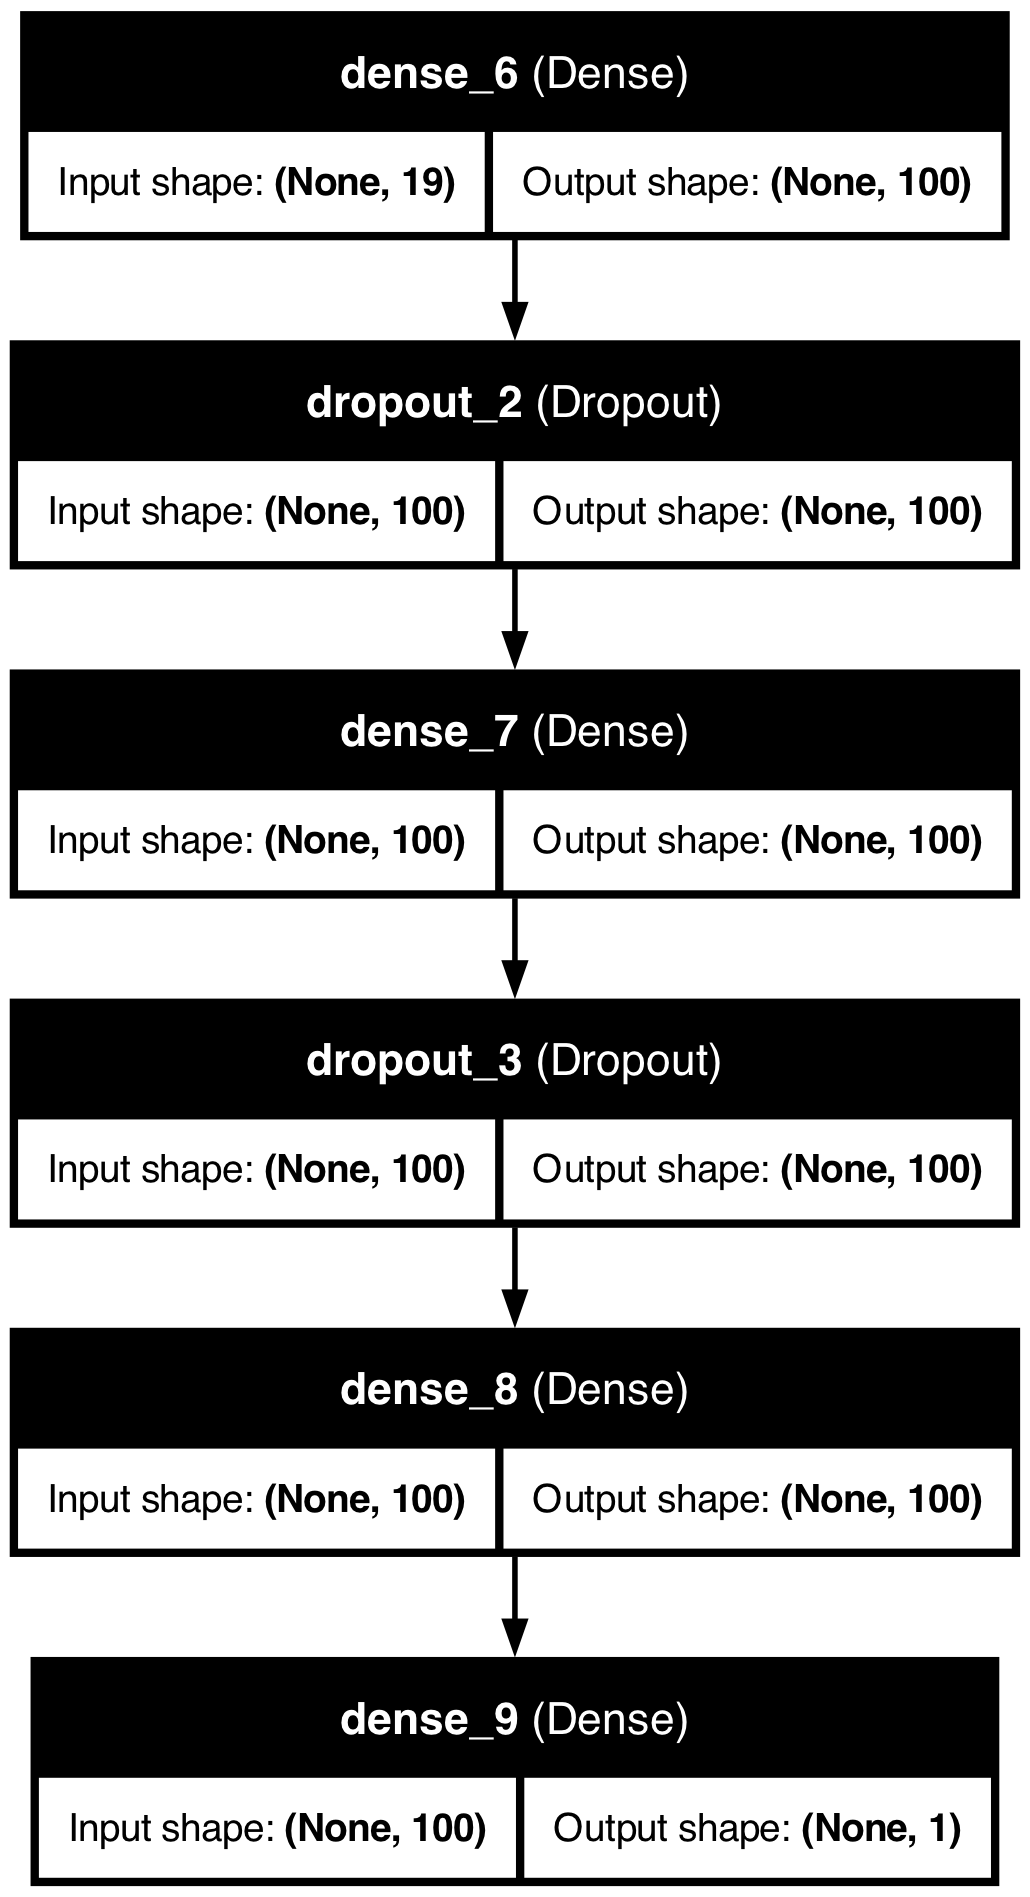

In [36]:
plot_model(model, to_file='model_architecture.png', show_shapes=True, show_layer_names=True)


In [37]:
model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=1000,
    batch_size=128,
)

Epoch 1/1000
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - loss: 888943.3125 - mean_absolute_error: 689.6650 - val_loss: 782761.7500 - val_mean_absolute_error: 629.6751
Epoch 2/1000
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - loss: 462200.3750 - mean_absolute_error: 461.3077 - val_loss: 223564.9531 - val_mean_absolute_error: 346.5206
Epoch 3/1000
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - loss: 194211.9219 - mean_absolute_error: 315.0374 - val_loss: 178150.9844 - val_mean_absolute_error: 299.8095
Epoch 4/1000
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 170371.6875 - mean_absolute_error: 291.2643 - val_loss: 169416.9062 - val_mean_absolute_error: 287.7931
Epoch 5/1000
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - loss: 163392.6406 - mean_absolute_error: 281.1267 - val_loss: 165515.8906 - val_mean_absolute_error: 281.3107
Epoch 6/1000
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - loss: 159158.9844 - mean_absolute_error: 276.1544 - val_loss: 162417.4844 - val_mean_absolute_error: 276.3995
Epoch 7/10

Let us see the loss evolution during training and check if there was overfitting.


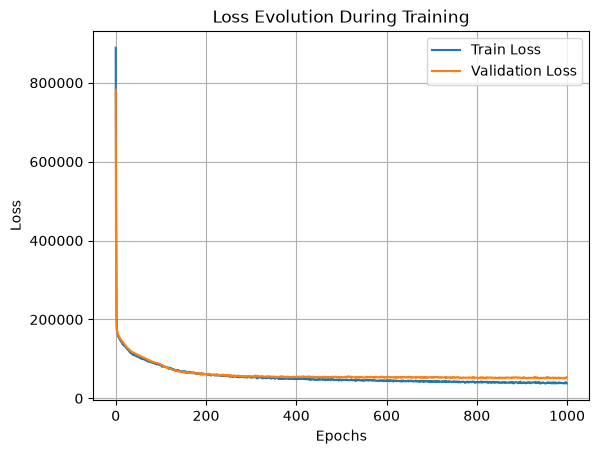

In [38]:
history = model.history
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Loss Evolution During Training')
plt.legend()
plt.grid()
plt.show()

The validation loss stops improving while the training loss still falls: overfitting. Do not pick the epoch count by eye.

**Early stopping** is not part of `Sequential` or `compile`. It is a *callback*, built before `fit` and passed as `callbacks=[...]`. `patience` is an argument of `EarlyStopping`: how many epochs with no improvement on the monitored quantity (here `val_loss`) to wait before stopping. `restore_best_weights=True` puts back the weights from the best validation epoch, not the last one.


In [ ]:
from keras.callbacks import EarlyStopping

tf.random.set_seed(42)

model = Sequential()
model.add(Input(shape=(n,)))
model.add(Dense(100, activation='relu'))
model.add(Dropout(0.1))
model.add(Dense(100, activation='relu'))
model.add(Dropout(0.1))
model.add(Dense(100, activation='relu'))
model.add(Dense(1))

model.compile(
    optimizer='adam',
    loss='mean_squared_error',
    metrics=['mean_absolute_error'],
)


early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True,
)

model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=1000,
    batch_size=128,
    callbacks=[early_stopping],
)


Epoch 1/1000
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - loss: 891637.5000 - mean_absolute_error: 691.0160 - val_loss: 788772.8750 - val_mean_absolute_error: 631.6609
Epoch 2/1000
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - loss: 465539.2500 - mean_absolute_error: 462.9185 - val_loss: 228612.1094 - val_mean_absolute_error: 358.3199
Epoch 3/1000
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - loss: 202103.4375 - mean_absolute_error: 324.8282 - val_loss: 184232.5000 - val_mean_absolute_error: 305.8764
Epoch 4/1000
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - loss: 175576.7500 - mean_absolute_error: 296.2872 - val_loss: 172754.1094 - val_mean_absolute_error: 290.2593
Epoch 5/1000
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - loss: 166093.9531 - mean_absolute_error: 284.5562 - val_loss: 167755.0312 - val_mean_absolute_error: 283.2977
Epoch 6/1000
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - loss: 161708.0625 - mean_absolute_error: 278.4525 - val_loss: 164166.8750 - val_mean_absolute_error: 278.2919
Epoch 7/10

Let us evaluate the model on the test data.


In [ ]:
res = model.evaluate(X_test, y_test)
print(f'Test loss: {res[0]:.4f}')
print(f'MAE: {res[1]:.4f}')


If wanted, we can compute the R² score, using the sklearn.metrics.r2_score function.


In [ ]:
from sklearn.metrics import r2_score
y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)
print(f'R²: {r2:.4f}')


And now, we can plot the predicted values against the true values.


In [ ]:
plt.plot(y_test, y_pred, 'o')
plt.plot([0, 2500], [0, 2500], '-', label='test')


## Dropout, L1, and L2 Regularization

Dropout, L1, and L2 are ways to limit overfitting. Dropout was already in the networks above. L1 penalises the sum of absolute weights. L2 penalises the sum of squared weights. Here the first hidden layer uses L1, the second uses L2, and the third uses both.


In [ ]:
model = Sequential()
model.add(Input(shape=(n,)))
model.add(Dense(100, activation='relu', kernel_regularizer='l1'))
model.add(Dropout(0.1))
model.add(Dense(100, activation='relu', kernel_regularizer='l2'))
model.add(Dropout(0.1))
model.add(Dense(100, activation='relu', kernel_regularizer='l1l2'))
model.add(Dense(1))
model.compile(
    optimizer='adam',
    loss='mean_squared_error',
    metrics=['mean_absolute_error']
)
model.fit(X_train, y_train,
          validation_data=(X_val, y_val),
          epochs=400,
          batch_size=32)
res = model.evaluate(X_test, y_test)
print(f'Test loss: {res[0]:.4f}')
print(f'MAE: {res[1]:.4f}')
y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)
print(f'R²: {r2:.4f}')
plt.plot(y_test, y_pred, 'o')
plt.plot([0, 2500], [0, 2500], '-', label='test')
